# Автор решения: Иванова Виктория

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

# Блок 1.

## Задача 1.1.

$E[X] = \sum x_i p_i = 0\cdot0{,}6 + 300\cdot0{,}3 + 1000\cdot0{,}08 + 5000\cdot0{,}02 = 0 + 90 + 80 + 100 = 270$

$E[X^2] = 300^2\cdot0{,}3 + 1000^2\cdot0{,}08 + 5000^2\cdot0{,}02 = 27\,000 + 80\,000 + 500\,000 = 607\,000$

$Var(X) = E[X^2] - (E[X])^2 = 607\,000 - 270^2 = 607\,000 - 72\,900 = 534\,100$

**Ответ:** $E[X] = 270$ руб., $Var(X) = 534\,100$ руб.^2

## Задача 1.2.

Число покупок $X \sim Bin(n=200,\ p=0{,}04)$ (визиты независимы, у каждого одна и та же вероятность покупки).

$E[X] = np = 200\cdot0{,}04 = 8$

$Var(X) = np(1-p) = 200\cdot0{,}04\cdot0{,}96 = 7{,}68$, $\sigma = \sqrt{7{,}68} \approx 2{,}77$

**Ответ:** $E[X] = 8$, $Var(X) \approx 2{,}77$.

## Задача 1.3.

По формулам: $E[X] = \frac{a+b}{2} = \frac{1+5}{2} = 3$ мин, $Var(X) = \frac{(b-a)^2}{12} = \frac{16}{12} = \frac43 \approx 1{,}33$ мин.^2

Плотность равномерного распределения $f(x) = \frac{1}{b-a}$ на $[a, b]$.

$$E[X] = \int_a^b x\cdot\frac{1}{b-a}\,dx = \frac{1}{b-a}\cdot\frac{b^2-a^2}{2} = \frac{a+b}{2}$$

$$E[X^2] = \int_a^b \frac{x^2}{b-a}\,dx = \frac{b^3-a^3}{3(b-a)} = \frac{a^2+ab+b^2}{3}$$

$$Var(X) = \frac{a^2+ab+b^2}{3} - \frac{(a+b)^2}{4} = \frac{4a^2+4ab+4b^2-3a^2-6ab-3b^2}{12} = \frac{(b-a)^2}{12}$$

**Ответ:** $E[X] = 3$ мин, $Var(X) \approx 1{,}33$.

## Задача 1.4.

**а) Сколько из 500 соискателей откликнутся - биномиальное** $Bin(500, p)$. Есть фиксированное число независимых испытаний (500 соискателей), в каждом два исхода (откликнулся / нет) с одной и той же вероятностью $p$, а считаем число «успехов».

**б) Время работы сервера до сбоя - экспоненциальное.** Сбои случаются случайно и не зависят от того, сколько сервер уже проработал (отсутствие памяти), а это как раз характерное свойство экспоненциального распределения.

**в) Рост взрослого человека - нормальное.** Рост складывается из множества небольших независимых факторов (генетика, питание и т.д.), поэтому по ЦПТ значения группируются вокруг среднего симметричным колоколом.

**г) Ежемесячный платёж по кредитной карте - распределение с тяжёлым правым хвостом**. У большинства платежи небольшие, у малой доли очень большие, то есть данные несимметричны и перекошены вправо. Самой подходящей считаю либо экспоненциальное, либо логнормальное.

# Блок 2. Симуляции в Python

## Задание 2.1.

$X \sim N(\mu, \sigma^2)$, где $\mu = 40$, $\sigma = 8$. 

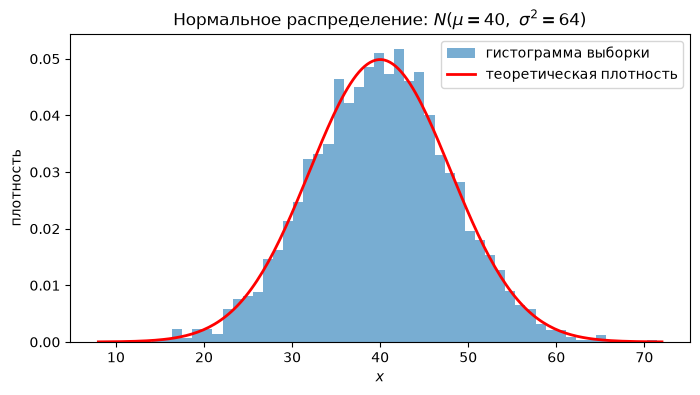

Выборочное среднее: 40.045 (теоретическое 40)

Выборочная дисперсия: 63.550 (теоретическая 64)

Выборочное стандартное отклонение: 7.972 (теоретическое 8)


In [48]:
mu, sigma = 40, 8
n_obs = 5000
sample = np.random.normal(mu, sigma, size=n_obs)

x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 200)
plt.figure(figsize=(8, 4))
plt.hist(sample, bins=50, density=True, alpha=0.6, label='гистограмма выборки')
plt.plot(x, stats.norm.pdf(x, mu, sigma), 'r', lw=2, label=r'теоретическая плотность')
plt.title(rf'Нормальное распределение: $N(\mu={mu},\ \sigma^2={sigma**2})$')
plt.xlabel('$x$')
plt.ylabel('плотность')
plt.legend()
plt.show()

print(
    f'Выборочное среднее: {sample.mean():.3f} (теоретическое {mu})\n\n'
    f'Выборочная дисперсия: {sample.var(ddof=1):.3f} (теоретическая {sigma**2})\n\n'
    f'Выборочное стандартное отклонение: {sample.std(ddof=1):.3f} (теоретическое {sigma})'
)

**Вывод.** Гистограмма выборки очень похожа на теоретическую плотность $f(x)$. Выборочные моменты близки к теоретическим:

| Характеристика | Теоретическое значение | Выборочное значение |
|---|---|---|
| Среднее | $40$ | $40{,}045$ |
| Дисперсия | $64$ | $\approx 63{,}55$ |
| Стандартное отклонение | $8$ | $7{,}972$ |


## Задание 2.2. Биномиальное распределение

$X \sim Bin(n, p)$, где $n = 1000$, $p = 0{,}04$.
 
Математическое ожидание: $E[X] = np = 1000 \cdot 0{,}04 = 40$

Дисперсия: $Var(X) = np(1-p) = 1000 \cdot 0{,}04 \cdot 0{,}96 = 38{,}4$

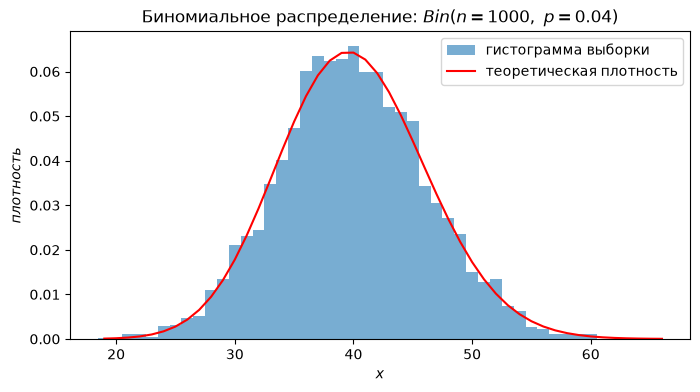

Выборочное среднее: 39.927 (теоретически 40)

Выборочная дисперсия: 38.710 (теоретически 38.400)

Выборочное стандартное отклонение: 6.222 (теоретически 6.197)


In [53]:
n, p = 1000, 0.04
sample = np.random.binomial(n, p, size=5000)

k = np.arange(sample.min(), sample.max() + 1)
plt.figure(figsize=(8, 4))
plt.hist(sample, bins=k - 0.5, density=True, alpha=0.6, label='гистограмма выборки')
plt.plot(k, stats.binom.pmf(k, n, p), 'r-', ms=4, label=r'теоретическая плотность')
plt.title(rf'Биномиальное распределение: $Bin(n={n},\ p={p})$')
plt.xlabel('$x$')
plt.ylabel(r'$плотность$')
plt.legend()
plt.show()

print(
    f'Выборочное среднее: {sample.mean():.3f} (теоретически {n * p:.0f})\n\n'
    f'Выборочная дисперсия: {sample.var(ddof=1):.3f} '
    f'(теоретически {n * p * (1 - p):.3f})\n\n'
    f'Выборочное стандартное отклонение: {sample.std(ddof=1):.3f} '
    f'(теоретически {np.sqrt(n * p * (1 - p)):.3f})'
)

**Вывод.** Гистограмма выборки очень похожа на теоретическую плотность. Выборочные моменты близки к теоретическим:

| Характеристика | Теоретическое значение | Выборочное значение |
|---|---|---|
| Среднее | $40$ | $39{,}927$ |
| Дисперсия | $38{,}4$ | $\approx 38{,}71$ |
| Стандартное отклонение | $6{,}197$ | $6{,}222$ |

Небольшие расхождения вызваны случайностью выборки.

## Задание 2.3. Центральная предельная теорема на экспоненциальном распределении

$X \sim Exp$ со средним $\mu = 1500$ (параметр $\lambda = 1/\mu$). 

$E[X] = \mu = 1500$

$Var(X) = \mu^2$, то есть $\sigma = \mu = 1500$

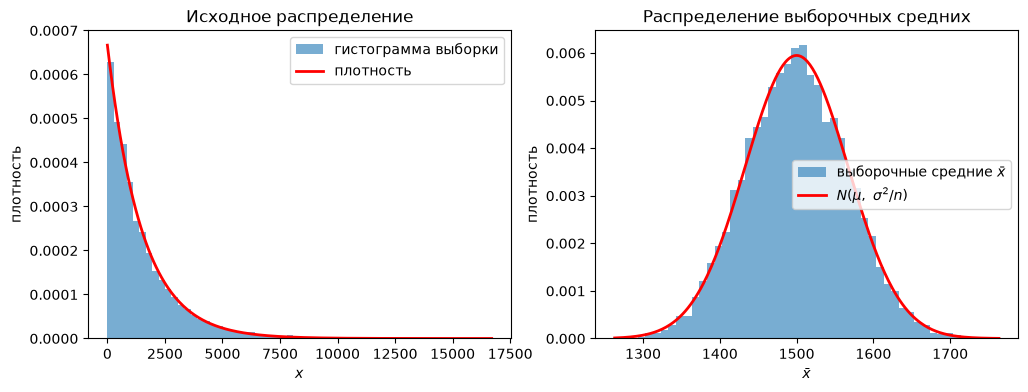

Среднее выборочных средних: 1500.0 (теоретически 1500)

Стандартное отклонение выборочных средних: 66.9 (теоретически 67.1)


In [50]:
scale = 1500       
n_obs = 500
n_sim = 10000

means = np.array([
    np.random.exponential(scale=scale, size=n_obs).mean()
    for _ in range(n_sim)
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# исходное распределение
raw = np.random.exponential(scale=scale, size=n_obs * 20)
xr = np.linspace(0, raw.max(), 300)
axes[0].hist(raw, bins=60, density=True, alpha=0.6, label='гистограмма выборки')
axes[0].plot(xr, stats.expon.pdf(xr, scale=scale), 'r', lw=2, label=r'плотность')
axes[0].set_title(rf'Исходное распределение')
axes[0].set_xlabel('$x$')
axes[0].set_ylabel('плотность')
axes[0].legend()

# распределение средних
se = scale / np.sqrt(n_obs)
xm = np.linspace(means.min(), means.max(), 300)
axes[1].hist(means, bins=50, density=True, alpha=0.6, label=r'выборочные средние $\bar{x}$')
axes[1].plot(xm, stats.norm.pdf(xm, scale, se), 'r', lw=2, label=r'$N(\mu,\ \sigma^2/n)$')
axes[1].set_title(rf'Распределение выборочных средних')
axes[1].set_xlabel(r'$\bar{x}$')
axes[1].set_ylabel('плотность')
axes[1].legend()
plt.show()

print(
    f'Среднее выборочных средних: {means.mean():.1f} (теоретически {scale})\n\n'
    f'Стандартное отклонение выборочных средних: {means.std(ddof=1):.1f} '
    f'(теоретически {se:.1f})'
)

**Вывод.** Исходное распределение сильно скошено вправо и совсем не похоже на колокол. При этом гистограмма средних $\bar{x}$ по $n = 500$ значений симметрична и хорошо ложится на нормальную кривую $N(\mu, \sigma^2/n)$ с центром в $\mu = 1500$ и стандартным отклонением $\sigma/\sqrt{n} \approx 67$.

Так происходит из-за ЦПТ: среднее - это сумма большого числа независимых слагаемых, у которых конечная дисперсия. Большие и малые отклонения в разные стороны взаимно гасятся, поэтому средние распределены примерно нормально.

# Блок 3. Мини-кейс про кнопку

## Задание 3.1. Стандартная ошибка конверсии

$SE = \sigma/\sqrt{n}$, где $\sigma = \sqrt{p(1-p)}$, $n = 5000$.

**Старая кнопка:** $p_1 = 0{,}031$

$\sigma_1 = \sqrt{p_1(1-\hat p_1)} = \sqrt{0{,}031\cdot0{,}969} \approx 0{,}1733$

$SE_1 = \dfrac{\sigma_1}{\sqrt{n}} = \dfrac{0{,}1733}{\sqrt{5000}} \approx \dfrac{0{,}1733}{70{,}71} \approx 0{,}00245$, то есть $\approx 0{,}245$ п.п.

**Новая кнопка:** $p_2 = 0{,}034$

$\sigma_2 = \sqrt{0{,}034\cdot0{,}966} \approx 0{,}1812$

$SE_2 = \dfrac{0{,}1812}{\sqrt{5000}} \approx 0{,}00256$, то есть $\approx 0{,}256$ п.п.


**Вывод.** Стандартная ошибка конверсии у старой кнопки $\approx 0{,}245$ п.п., у новой $\approx 0{,}256$ п.п. Разница в $0{,}3$ п.п. сопоставима с ошибкой каждой из оценок. Значит, разница в $0{,}3$ п.п. находится в пределах обычных случайных колебаний, и предварительно её нельзя считать эффектом: вполне возможно, что это шум.

## Задание 3.2. Проверка симуляцией

Предполагаем, что у обеих групп конверсия одна и та же: $p = (155 + 170)/10\,000 = 3{,}25\%$. 100 000 раз моделируем пару групп по 5000 соискателей и смотрим на разницу конверсий.

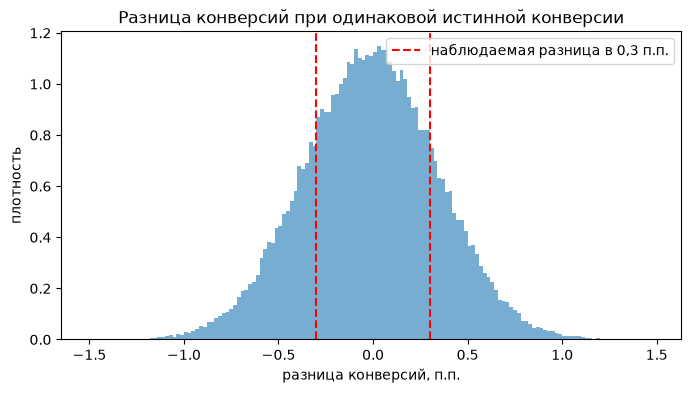

Доля повторов с разницей >= +0,3 п.п.: 0.196
Доля повторов с |разницы| >= 0,3 п.п.: 0.396


In [51]:
p = (155 + 170) / 10_000
n = 5000
n_sim = 100_000

old = np.random.binomial(n, p, size=n_sim) / n
new = np.random.binomial(n, p, size=n_sim) / n
diffs = new - old

observed = 0.003
p_one = (diffs >= observed).mean()
p_two = (np.abs(diffs) >= observed).mean()

plt.figure(figsize=(8, 4))
plt.hist(diffs * 100, bins=np.arange(-1.5, 1.5, 0.02), density=True, alpha=0.6)
plt.axvline(observed * 100, color='red', ls='--', label='наблюдаемая разница в 0,3 п.п.')
plt.axvline(-observed * 100, color='red', ls='--')
plt.title('Разница конверсий при одинаковой истинной конверсии')
plt.xlabel('разница конверсий, п.п.')
plt.ylabel('плотность')
plt.legend()
plt.show()

print(f'Доля повторов с разницей >= +0,3 п.п.: {p_one:.3f}')
print(f'Доля повторов с |разницы| >= 0,3 п.п.: {p_two:.3f}')

**Вывод.** Мы предположили, что у обеих кнопок одна и та же истинная конверсия $p = 3{,}25\%$, и 100 000 раз смоделировали пару групп по $n = 5000$. Получилось:

- разница конверсий в группах $p_2 - p_1 \ge +0{,}3$ п.п. встречается в $\approx 20\%$ повторов
- разница не меньше $0{,}3$ п.п. по модулю, то есть в любую сторону, встречается в $\approx 40\%$ повторов.

Значит, даже если новая кнопка ничего не меняет, такое или большее превосходство мы бы увидели в каждом пятом эксперименте. Это обычное случайное колебание, поэтому наблюдаемые $+0{,}3$ п.п. не доказывают эффекта. 

**Итог:** это шум, а не доказанный эффект.

## Задание 3.3. Выбросы во времени сессии

In [52]:
t = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

# правило трёх сигм
mean, std = t.mean(), t.std(ddof=1)
upper_3s = mean + 3 * std
print(f'1) Граница 3 сигм: {upper_3s:.1f}; выбросы: {t[t > upper_3s]}')

# перцентили
q1, q3 = np.percentile(t, [25, 75])
upper_pct = q3 + 1.5 * (q3 - q1)
print(f'2) Граница по перцентилям: {upper_pct:.2f}; выбросы: {t[t > upper_pct]}')

# без выброса
t_clean = t[t != 52]
print(f'\nСреднее: {t.mean():.1f} и медиана: {np.median(t):.1f} с выбросом')
print(f'Среднее: {t_clean.mean():.2f} и медиана: {np.median(t_clean):.1f} без выброса')

1) Граница 3 сигм: 54.5; выбросы: []
2) Граница по перцентилям: 10.50; выбросы: [52]

Среднее: 10.0 и медиана: 5.5 с выбросом
Среднее: 5.33 и медиана: 5.0 без выброса


**Вывод.**

Лучше сработал способ с перцентилями. Правило трёх сигм не увидело выброс, потому что сам выброс участвует в расчёте: он влияет на среднее (10 мин вместо $\approx 5{,}3$ без него) и особенно стандартное отклонение (14,8 мин при типичных значениях 3–8), и граница двинулась дальше самого значения 52. Перцентили зависят от порядка значений, а не от их величины: будь выброс хоть 500 минут, границы остались бы теми же, поэтому они устойчивы к выбросам и хорошо работают на данных с длинным хвостом.